In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as pl
import seaborn as sns
import yaml
from pathlib import Path
from tqdm.auto import tqdm

# !pip install tslearn minisom --quiet
from tslearn.barycenters import dtw_barycenter_averaging as dba
from tslearn.clustering import TimeSeriesKMeans

# make figures paper quality
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
# Arial font
matplotlib.rcParams['font.sans-serif'] = "Arial"
matplotlib.rcParams['font.family'] = "sans-serif"

import warnings
warnings.filterwarnings("ignore")

In [7]:
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)

seq_primer = config['primer_seq']  # sequence left of gRNA
guide_length = config['guide_length']
# primer will appear between min and max position
pmin, pmax = config['primer_range']['min'], config['primer_range']['max']

path = Path(config['TEMPDIR']) / 'pooled_screen_1/'
cell_line_dict={
    '01': 'H1975',
    '02': 'H1299',
    '03': 'A549'
}

# Prepare the Data

In [77]:
# Define data
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts_filtered.csv', index_col=0)

sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
sample_names_wo_pools = [x for x in sample_names if not any([p in x for p in pools])]
controls = [x for x in df.index if 'control' in x.lower()]

In [78]:
# Normalize to NT depth
norm_factor = df.loc[controls, pools].mean(axis=1).mean() / df.loc[controls, sample_names].mean(axis=0)
ndf = df.loc[:, sample_names] * norm_factor

# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T
l2fc = np.log2(fc)
l2fc[l2fc==-np.infty] = None

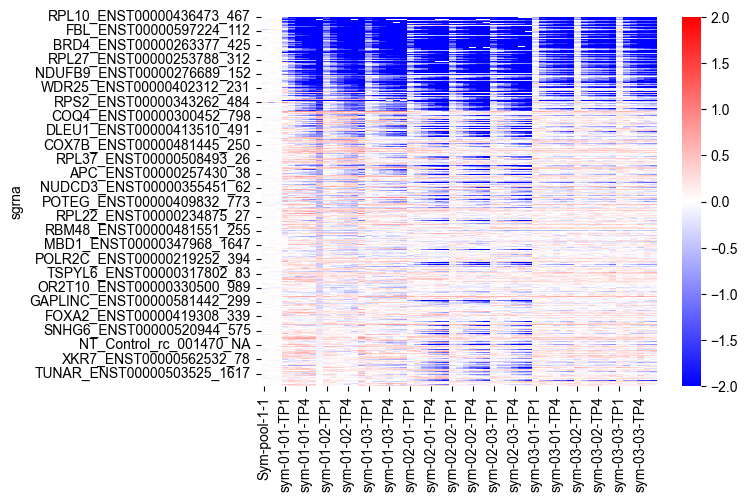

In [79]:
# sanity check
sns.heatmap(l2fc, cmap='bwr', center=0, vmin=-2, vmax=2); 

In [80]:
# annotate
tab = l2fc.iloc[:, 3:].T
tab['time'] = [x.split('-')[-1] for x in tab.index]
tab['replicate'] = [x.split('-')[2] for x in tab.index]
tab['cell_line'] = [cell_line_dict[x.split('-')[1]] for x in tab.index]

In [81]:
# mean over replicates
mtab = tab.fillna(0).drop('replicate', axis=1).groupby(['cell_line', 'time']).mean()  

In [82]:
cell_line = list(cell_line_dict.values())[0]

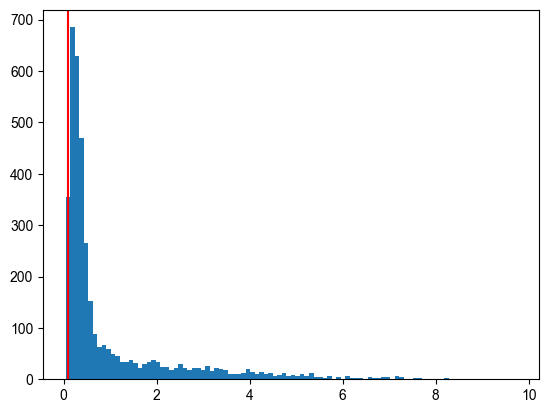

In [83]:
# remove guides with too low signal
eps = 0.1
pl.hist(mtab.loc[cell_line].abs().max(), bins=100)
pl.axvline(eps, color='r')
pl.show()

In [84]:
# Do analysis on each line separately
from sklearn.preprocessing import MinMaxScaler
data = mtab.loc[cell_line]
data = data.loc[:, data.abs().max() > eps]
scaler = MinMaxScaler()
Y = scaler.fit_transform(data)

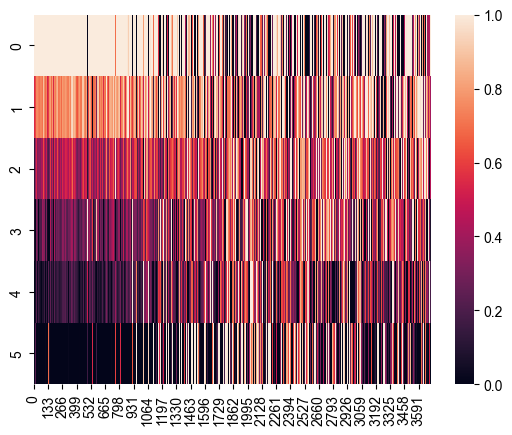

In [85]:
# sanity check
sns.heatmap(Y)
pl.show()

# Clustering

We perform Time-series K-means clustering on the data. We will use the `tslearn` library for this purpose. Guide: 
https://www.kaggle.com/code/izzettunc/introduction-to-time-series-clustering

In [88]:
# Define number of clusters
K = 5  
km = TimeSeriesKMeans(n_clusters=K, metric="dtw")

In [89]:
# Fit K-Means and get labels (2mins)
labels = km.fit_predict(Y.T)
res = pd.DataFrame(Y.T, index = data.columns)
res['label'] = labels

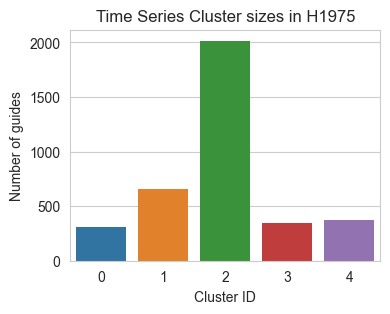

In [90]:
# plot as bars
cts = np.unique(labels, return_counts=True)
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots(1, 1, figsize=(4, 3))
sns.barplot(x=cts[0], y=cts[1], ax=ax)
pl.title(f'Time Series Cluster sizes in {cell_line}', fontsize=12)
pl.xlabel('Cluster ID')
pl.ylabel('Number of guides')
pl.savefig(f'../results/timecourse/time_series_cluster_sizes_{cell_line}.pdf', bbox_inches='tight')
pl.show()

In [91]:
# Calculate representative time series for each cluster
reps = res.groupby('label').mean()
reps_ = {label: np.ravel(dba(res[res['label']==label].drop('label', axis=1).values)) for label in tqdm(np.unique(labels))}
reps_ = pd.DataFrame(reps_).T

  0%|          | 0/5 [00:00<?, ?it/s]

In [92]:
# distance from reps to quantify goodness of fit
from tslearn.metrics import dtw
scores = pd.DataFrame(index=res.index, columns=['label', 'dtw'])
for label in tqdm(reps_.index):
    mask = res['label']==label
    data = res[mask].drop('label', axis=1).values
    scores.loc[mask, 'dtw'] = [dtw(reps_.loc[label], x) for x in data]
    scores.loc[mask, 'label'] = label
scores['score'] = - np.log(np.array(scores['dtw'].fillna(0).values, dtype=float))

  0%|          | 0/5 [00:00<?, ?it/s]

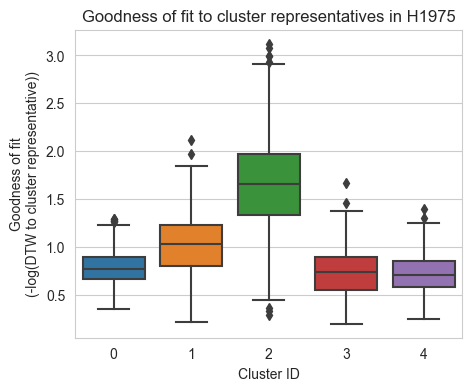

In [93]:
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots(1, 1, figsize=(5, 4))
sns.boxplot(x='label', y='score', data=scores)
pl.ylabel('Goodness of fit\n(-log(DTW to cluster representative))')
pl.xlabel('Cluster ID')
pl.title(f'Goodness of fit to cluster representatives in {cell_line}')
pl.show()

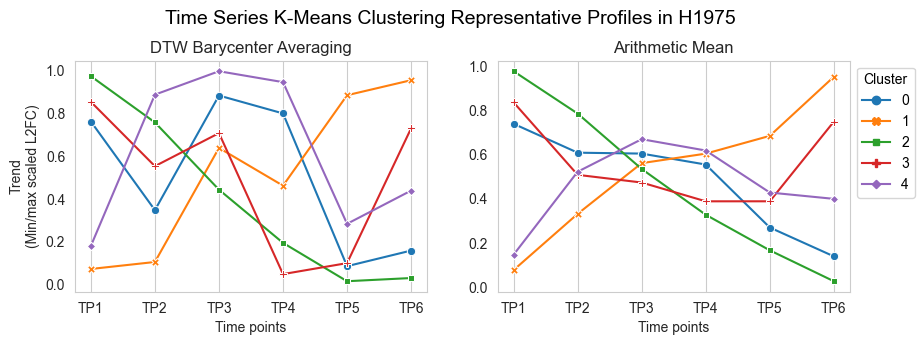

In [94]:
with sns.axes_style('whitegrid'):
    fig, axs = pl.subplots(1, 2, figsize=(10, 3))
ax = axs[0]
sns.lineplot(data=reps_.T, dashes=False, markers=True, ax=ax)
ax.legend_.remove()
ax.set_title('DTW Barycenter Averaging')
ax.set_ylabel('Trend\n(Min/max scaled L2FC)')

ax = axs[1]
sns.lineplot(data=reps.T, dashes=False, markers=True, ax=ax)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1), title='Cluster')
ax.set_title('Arithmetic Mean')

for ax in axs:
    ax.set_xlabel('Time points')
    ax.set_xticks([0, 1, 2, 3, 4, 5], ['TP1', 'TP2', 'TP3', 'TP4', 'TP5', 'TP6'])
    ax.grid(axis='y')

pl.suptitle(f'Time Series K-Means Clustering Representative Profiles in {cell_line}', y=1.05, fontsize=14)
pl.savefig(f'../results/timecourse/time_series_cluster_representatives_{cell_line}.pdf', bbox_inches='tight')
pl.show()

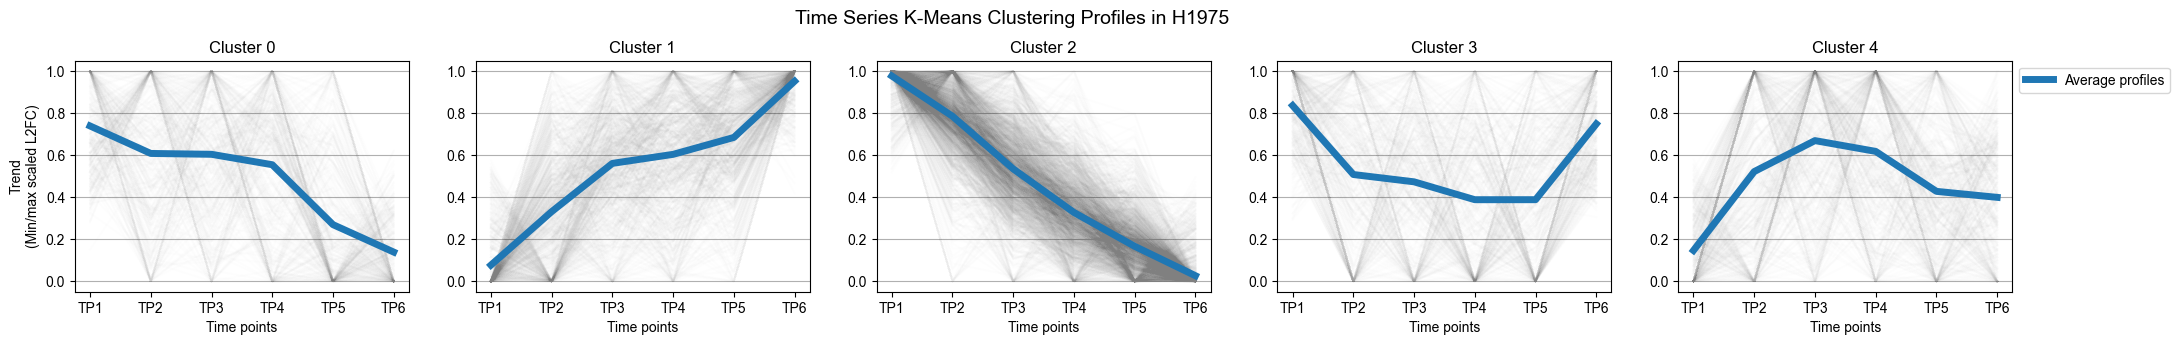

In [95]:
fig, axs = pl.subplots(1, K, figsize=(K*5, 3))
R = reps
for k in range(K):
    ax = axs[k]
    data = res[res['label']==k].drop('label', axis=1).values
    ax.plot(R.T[k], 
            label='Average profiles',
            # label='DTW Barycenter Average', 
            linewidth=5, zorder=10)
    for i in range(len(data)):
        ax.plot(data[i], alpha=0.01, color='grey')
    ax.set_title(f'Cluster {k}')
    ax.set_xlabel('Time points')
    if ax==axs[0]: ax.set_ylabel('Trend\n(Min/max scaled L2FC)')
    if ax==axs[-1]: ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    ax.set_xticks([0, 1, 2, 3, 4, 5], ['TP1', 'TP2', 'TP3', 'TP4', 'TP5', 'TP6'])
    ax.grid(axis='y')
pl.suptitle(f'Time Series K-Means Clustering Profiles in {cell_line}', y=1.05, fontsize=14)
pl.savefig(f'../results/timecourse/time_series_cluster_profiles_{cell_line}.pdf', bbox_inches='tight')
pl.show()

In [99]:
# save scores and cluster assignments
scores.to_csv(f"../results/timecourse/timecourse_clusters_{cell_line}.csv")
# get best representing guides for each cluster
bests = {label: scores[scores['label']==label].sort_values('score', ascending=False).index for label in np.unique(labels)}
# Rank guides by their distance to the cluster representative
tops = pd.DataFrame(dict([ (k,pd.Series(v)) for k,v in bests.items() ]))
tops.columns = [f'Cluster_{x}' for x in tops.columns]
tops.to_csv(f"../results/timecourse/timecourse_topgenes_{cell_line}.csv")

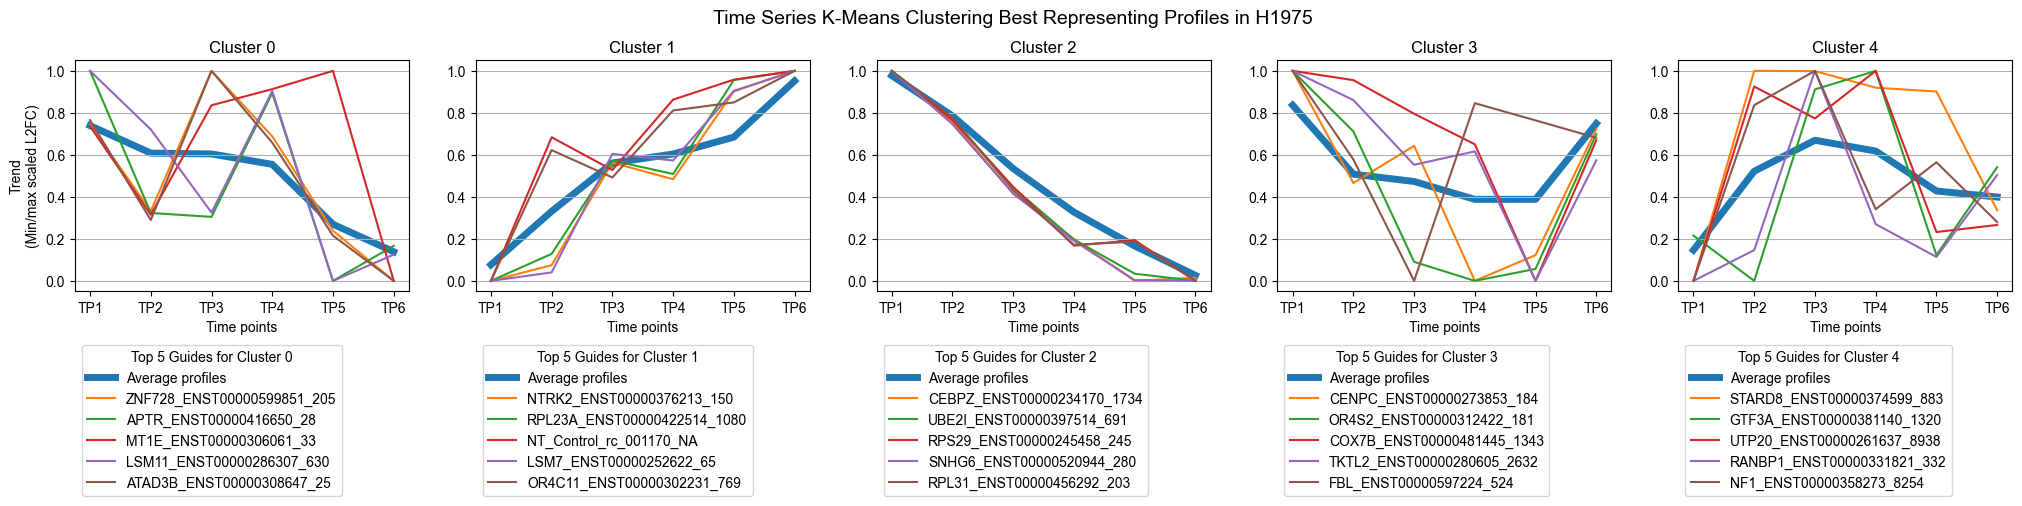

In [101]:
# Now plot those top guides
fig, axs = pl.subplots(1, K, figsize=(K*5, 3))
R = reps

for k in range(K):
    ax = axs[k]
    data = res[res['label']==k].drop('label', axis=1)
    ax.plot(R.T[k], 
            label='Average profiles',
            linewidth=5, zorder=-1)
    best = tops[f'Cluster_{k}'].values[:5]
    for guide in best:
        ax.plot(data.loc[guide].values, alpha=1, label=guide)
    ax.set_title(f'Cluster {k}')
    ax.set_xlabel('Time points')
    if ax==axs[0]: ax.set_ylabel('Trend\n(Min/max scaled L2FC)')
    ax.legend(loc='upper left', bbox_to_anchor=(0, -0.2), title='Top 5 Guides for Cluster '+str(k))
    ax.set_xticks([0, 1, 2, 3, 4, 5], ['TP1', 'TP2', 'TP3', 'TP4', 'TP5', 'TP6'])
    ax.grid(axis='y')
pl.suptitle(f'Time Series K-Means Clustering Best Representing Profiles in {cell_line}', y=1.05, fontsize=14)
pl.savefig(f'../results/timecourse/time_series_cluster_bestprofiles_{cell_line}.pdf', bbox_inches='tight')
pl.show()

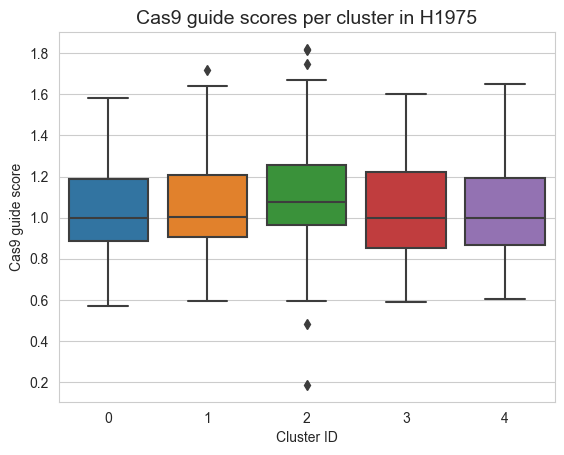

In [103]:
# CRISPR scores distribution per cluster (we expect that the "Falling" cluster has the highest score)
res['Cas9_guide_score'] = df.loc[res.index, 'Guide_Score']
with sns.axes_style('whitegrid'):
    sns.boxplot(x='label', y='Cas9_guide_score', data=res)
pl.ylabel('Cas9 guide score')
pl.xlabel('Cluster ID')
pl.title(f'Cas9 guide scores per cluster in {cell_line}', fontsize=14)
pl.savefig(f'../results/timecourse/time_series_cluster_cas9scores_{cell_line}.pdf', bbox_inches='tight')
pl.show()